# Phân loại cảm xúc đánh giá Điện Máy Xanh

| Bước | Nơi làm | Đầu ra |
|---|---|---|
| B1 Cào dữ liệu | `crawl_reviews.py` | `data/01.raw_reviews.csv` |
| B2 Làm sạch nhẹ | `clean_reviews.py` | `data/02.clean_reviews.csv` |
| B3 Gán nhãn | Người gán tay 500 câu, Claude gán toàn bộ theo `prompt_ai_label1.md` | `data/04.human_labels.xlsx`, `data/05.claude_v2.csv` |
| B3–B7 | **notebook này** | đọc nhãn → EDA → chia tập → tiền xử lý → đặc trưng → huấn luyện → đánh giá |

Nhãn: `-1` tiêu cực, `0` trung tính, `1` tích cực.

## Thiết lập thư viện

In [2]:
import re
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from underthesea import word_tokenize
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from gensim.models import Word2Vec
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
pd.set_option('display.max_colwidth', 120)
DATA, OUT = Path('data'), Path('out')
OUT.mkdir(exist_ok=True)
SEED = 42
LABELS, NAMES = [-1, 0, 1], ['Tiêu cực', 'Trung tính', 'Tích cực']
MAU = ['#d9534f', '#f0ad4e', '#5cb85c']  # màu của từng nhãn trong các biểu đồ


## 1. Dữ liệu và nhãn (B3)

Nhãn theo số sao có sẵn khi cào nhưng bị nhiễu: nhiều review 3 sao thực chất đang chê. Vì vậy nhóm gán lại theo **nội dung chữ**:

- `04.human_labels.xlsx`: nhóm gán tay 500 câu, **dùng làm tập test chuẩn**
- `05.claude_v2.csv`: Claude gán **toàn bộ** câu theo `prompt_ai_label1.md` (luật rút ra từ cách nhóm gán tay), **dùng làm nhãn huấn luyện**

In [3]:
# Dữ liệu đã làm sạch. nhan_sao là nhãn suy từ số sao lúc cào, chỉ dùng để so sánh.
df = pd.read_csv(DATA / '02.clean_reviews.csv')[['review_id', 'product_id', 'so_sao', 'noi_dung', 'nhom_cam_xuc']]
df['nhan_sao'] = df['nhom_cam_xuc'].map(dict(zip(NAMES, LABELS)))

# Nhãn AI cho toàn bộ câu: dùng để huấn luyện.
ai = pd.read_csv(DATA / '05.claude_v2.csv').set_index('review_id')['label']
assert ai.index.is_unique and set(ai.index) == set(df['review_id']), \
    '05 phải có đủ mọi câu của 02, mỗi câu một dòng (cào lại dữ liệu thì phải gán lại)'
assert ai.isin(LABELS).all(), '05: nhãn chỉ được là -1, 0, 1'
df['label'] = df['review_id'].map(ai)

# Nhãn người cho 500 câu: dùng làm tập test.
nguoi = pd.read_excel(DATA / '04.human_labels.xlsx').set_index('review_id')['label']
assert nguoi.notna().all(), f'04: còn {nguoi.isna().sum()} câu chưa gán nhãn'
nguoi = nguoi.astype(int)
assert nguoi.isin(LABELS).all() and nguoi.index.isin(df['review_id']).all()

print(f'{len(df):,} câu từ {df["product_id"].nunique()} sản phẩm | nhãn AI: {len(ai):,} câu | nhãn người: {len(nguoi)} câu')

5,493 câu từ 16 sản phẩm | nhãn AI: 5,493 câu | nhãn người: 500 câu


### Chất lượng nhãn: so với nhãn người (tỉ lệ khớp và Cohen's Kappa)

In [4]:
sao = df.set_index('review_id')['nhan_sao']

def so_voi_nguoi(nguon, nhan):
    nhan = nhan[nguoi.index]
    return {'Nguồn nhãn': nguon, 'Tỉ lệ khớp': (nhan == nguoi).mean(),
            "Cohen's Kappa": cohen_kappa_score(nguoi, nhan)}

display(pd.DataFrame([so_voi_nguoi('Số sao', sao), so_voi_nguoi('AI (Claude)', ai)]).round(3))
print('Lưu ý: luật trong prompt rút ra từ chính các câu này, nên độ khớp của nhãn AI ở đây cao hơn thực tế.')

,Nguồn nhãn,Tỉ lệ khớp,Cohen's Kappa
0,Số sao,0.768,0.604
1,AI (Claude),0.974,0.957


Lưu ý: luật trong prompt rút ra từ chính các câu này, nên độ khớp của nhãn AI ở đây cao hơn thực tế.


### Các câu AI gán khác người

In [5]:
lech = pd.DataFrame({'noi_dung': df.set_index('review_id')['noi_dung'][nguoi.index],
                     'nguoi': nguoi, 'ai': ai[nguoi.index]}).query('nguoi != ai')
print(f'{len(lech)}/{len(nguoi)} câu AI gán khác người')
lech

13/500 câu AI gán khác người


,noi_dung,nguoi,ai
review_id,,,
57241275,Máy lúc mới lắp thì chạy OK sau hơn 1 tháng sử dụng thì máy làm mát rất yếu gọi nhân viên xuống kiểm tra thì lại báo...,0,-1
56752347,"Sau 1 tuần sd thì thấycánh quạt khi đóng hở cả khúc côn trùng dễ vào, cánh cũng ko hạ sâu chỉ lơ lớ, dàn lạnh lâu lâ...",0,-1
58871869,"Tai nghe bên phải sử dụng chưa đc 2p thì hết pin mặc dù đã sạc 100%, còn bên trái đang có dấu hiệu tụt pin rất nhanh",0,-1
52800748,"Mẫu mã đẹp, về chất lượng thì khi nấu cần ấn nút 2 lần cơm mới chín",1,0
58025248,Điều khó chịu nhất là KHÔNG CÓ NHỚ VỊ TRÍ ĐÃ ĐI VÀ KHÔNG VẼ BẢN ĐỒ. Với tầm giá này thì đáng ra phải làm tốt hơn con...,1,0
56947827,Sao nút swing đảo gió lên xuống thì thấy có hoạt động còn nuta direct điều chỉnh hướng gió qua lại thì nhân vô nó ko...,0,-1
52212361,"Tạm thời thấy ko vấn đề gì, nv tư vấn nhiệt tình",0,1
46374685,Cho mình hỏi sao tủ của mình nóng vậy Chuyển tới mình để tới 3 tiếng mới ngăm điện ạ,-1,0
34038831,Em nói thật chứ mấy bác nên đọc kĩ hướng dẫn rồi hẵng sử dung Máy ngon trong tầm giá mát nói chung chỉ thế thôi.kaka,0,1


## 2. Khám phá dữ liệu (EDA)

Phân tích trên **toàn bộ** dữ liệu đã gán nhãn AI, trước khi chia tập.

### 2.1 Tổng quan

In [6]:
print('Kích thước:', df.shape)
print('Ô trống:', int(df[['noi_dung', 'label']].isna().sum().sum()),
      '| nội dung trùng:', int(df['noi_dung'].duplicated().sum()),
      '| review_id trùng:', int(df['review_id'].duplicated().sum()))
df[['noi_dung', 'so_sao', 'label']].sample(8, random_state=SEED)

Kích thước: (5493, 7)
Ô trống: 0 | nội dung trùng: 0 | review_id trùng: 0


,noi_dung,so_sao,label
1858,Tủ quá kêu kọt kẹt pòng nhỏ khó ngủ,1,-1
691,"Nồi cơm nấu bị trào, nấu cơm bị cháy dưới đáy, cơm bị khét dưới đít, nấu bị trào hơi nguy hiêm",2,-1
4564,Hút thì sạch xong chưa triệt để . Mau hết pin,4,0
1101,"Đã mua sản phẩm, giao hàng nhanh, uy tín, chất lượng, cơm chín nhanh, đáng để mua.",5,1
5006,"mình xài no gần 1 năm nhưng rất bền mẫu mã đẹp lại sang nữa, long nồi chong dính bằng gang rất dày, nấu cơm rất ngon...",5,1
1992,Giao hàng nhanh,4,1
439,Rất cám ơn.,5,0
5091,Nồi đổi 3 lần rồi bây giờ lại hư. Bực hết cả mình. Bây giờ tôi muốn đổi nồi khác không xài loại bày nữa thì làm sao ...,1,-1


### 2.2 Phân bố nhãn
Lớp trung tính ít hơn hẳn, nên các mô hình đặt `class_weight='balanced'` và được so bằng Macro F1.

,Số câu,Tỉ lệ (%)
Tiêu cực,1979,36.0
Trung tính,578,10.5
Tích cực,2936,53.4


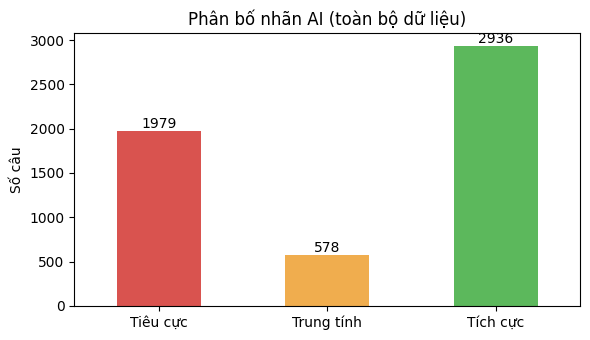

In [7]:
dem = df['label'].value_counts().reindex(LABELS)
display(pd.DataFrame({'Số câu': dem.values, 'Tỉ lệ (%)': (dem / len(df) * 100).round(1).values}, index=NAMES))
ax = dem.set_axis(NAMES).plot(kind='bar', rot=0, color=MAU, figsize=(6, 3.5))
ax.bar_label(ax.containers[0])
ax.set_title('Phân bố nhãn AI (toàn bộ dữ liệu)'); ax.set_ylabel('Số câu')
plt.tight_layout(); plt.show()

### 2.3 Nhãn AI so với số sao
Mỗi hàng là một nhóm số sao, ô là tỉ lệ (%) câu trong nhóm đó được gán từng nhãn.

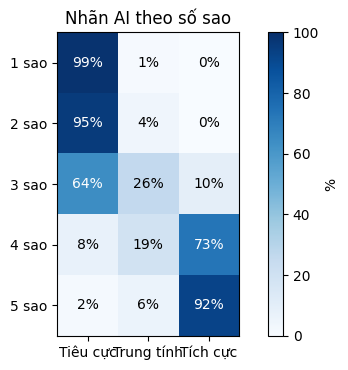

Nhãn AI khớp nhãn theo số sao: 80.4%


In [8]:
ti_le = pd.crosstab(df['so_sao'], df['label'], normalize='index').reindex(columns=LABELS) * 100
fig, ax = plt.subplots(figsize=(6, 3.8))
im = ax.imshow(ti_le.values, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(len(NAMES)), NAMES)
ax.set_yticks(range(len(ti_le)), [f'{s} sao' for s in ti_le.index])
for (i, j), v in np.ndenumerate(ti_le.values):
    ax.text(j, i, f'{v:.0f}%', ha='center', va='center', color='white' if v > 60 else 'black')
ax.set_title('Nhãn AI theo số sao'); fig.colorbar(im, ax=ax, label='%')
plt.tight_layout(); plt.show()
print(f'Nhãn AI khớp nhãn theo số sao: {(df["label"] == df["nhan_sao"]).mean():.1%}')

### 2.4 Độ dài review
Câu chê thường dài hơn vì người viết hay kể lại lỗi và quá trình bảo hành.

,count,mean,std,min,25%,50%,75%,max
Tiêu cực,1979.0,35.2,41.6,1.0,14.0,24.0,42.0,889.0
Trung tính,578.0,22.8,19.0,1.0,11.0,20.0,29.0,239.0
Tích cực,2936.0,15.3,15.7,1.0,5.0,11.0,21.0,238.0


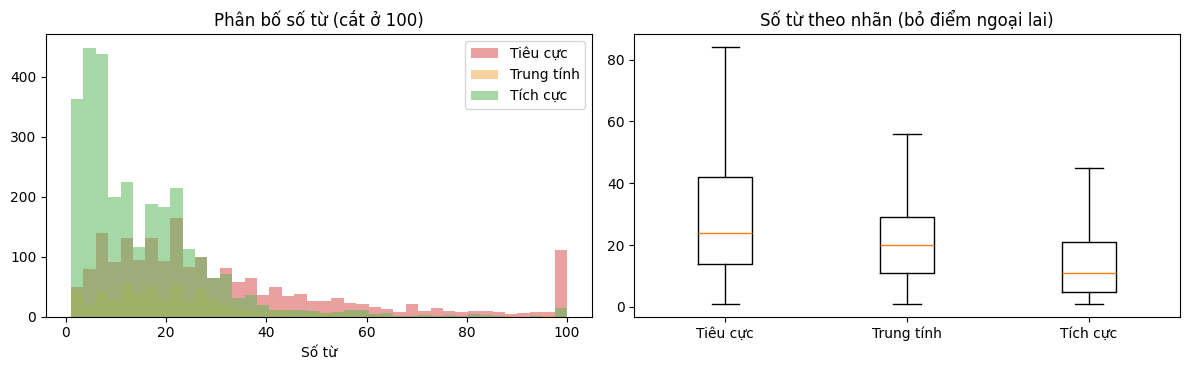

In [9]:
df['so_tu'] = df['noi_dung'].str.split().str.len()
display(df.groupby('label')['so_tu'].describe().round(1).set_axis(NAMES))
so_tu_theo_nhan = [df.loc[df['label'] == c, 'so_tu'] for c in LABELS]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for so_tu, ten, mau in zip(so_tu_theo_nhan, NAMES, MAU):
    ax[0].hist(so_tu.clip(upper=100), bins=40, alpha=0.55, label=ten, color=mau)
ax[0].set_title('Phân bố số từ (cắt ở 100)'); ax[0].set_xlabel('Số từ'); ax[0].legend()
ax[1].boxplot(so_tu_theo_nhan, showfliers=False)
ax[1].set_xticks([1, 2, 3], NAMES); ax[1].set_title('Số từ theo nhãn (bỏ điểm ngoại lai)')
plt.tight_layout(); plt.show()

### 2.5 Phân bố nhãn theo sản phẩm

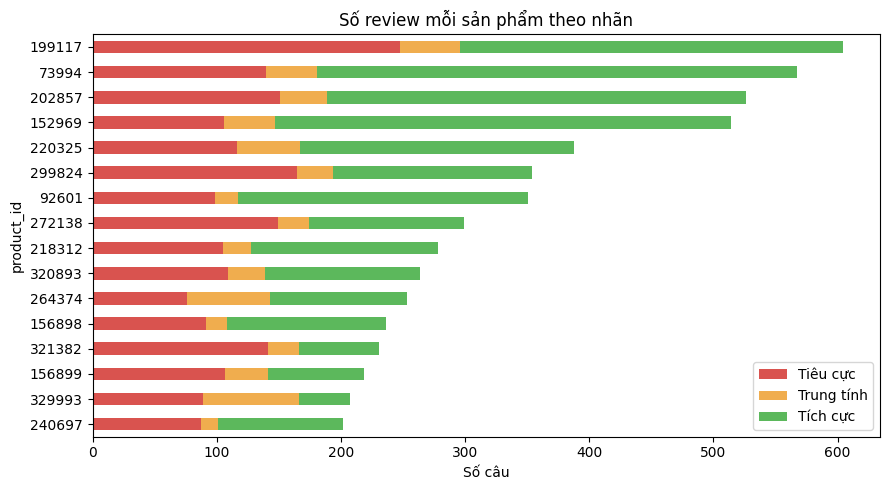

In [10]:
sp = pd.crosstab(df['product_id'], df['label']).reindex(columns=LABELS).set_axis(NAMES, axis=1)
sp = sp.loc[sp.sum(axis=1).sort_values(ascending=False).index]
ax = sp.plot(kind='barh', stacked=True, figsize=(9, 5), color=MAU)
ax.invert_yaxis(); ax.set_xlabel('Số câu'); ax.set_title('Số review mỗi sản phẩm theo nhãn')
plt.tight_layout(); plt.show()

### 2.6 Cụm 2 âm tiết hay gặp nhất theo nhãn
Tiếng Việt nhiều từ ghép 2 âm tiết ("hài lòng", "bảo hành"), nên đếm cụm 2 âm tiết liền nhau cho dễ đọc hơn đếm từng âm tiết.

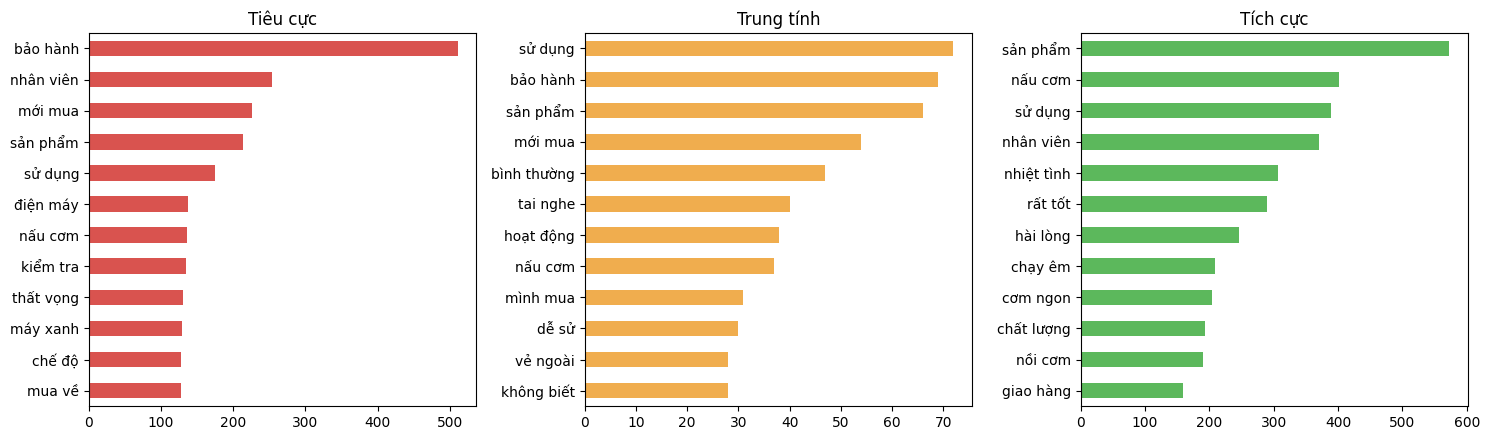

In [11]:
def cum_pho_bien(cac_cau, n=12):
    # Đếm cụm 2 âm tiết liền nhau, trả về n cụm nhiều nhất
    dem = CountVectorizer(ngram_range=(2, 2), token_pattern=r'(?u)\b\w+\b')
    tong = np.asarray(dem.fit_transform(cac_cau.str.lower()).sum(axis=0)).ravel()
    top = np.argsort(-tong)[:n]
    return pd.Series(tong[top], index=dem.get_feature_names_out()[top])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c, ten, mau in zip(axes, LABELS, NAMES, MAU):
    cum_pho_bien(df.loc[df['label'] == c, 'noi_dung'])[::-1].plot(kind='barh', ax=ax, color=mau)
    ax.set_title(ten)
plt.tight_layout(); plt.show()

## 3. Chia tập dữ liệu
- **Test**: các câu nhóm gán tay, dùng **nhãn người**
- **Validation**: 15% dữ liệu, dùng để chọn mức từ dừng và chọn mô hình
- **Train**: phần còn lại, dùng **nhãn AI**

Mỗi câu chỉ nằm trong một tập. Tập test chỉ dùng một lần ở cuối.

In [12]:
test = df[df['review_id'].isin(nguoi.index)].copy()
test['label'] = test['review_id'].map(nguoi)          # test dùng nhãn người
con_lai = df[~df['review_id'].isin(nguoi.index)]      # train và validation dùng nhãn AI
train, val = train_test_split(con_lai, test_size=round(0.15 * len(df)), stratify=con_lai['label'], random_state=SEED)
train, val = train.copy(), val.copy()
pd.DataFrame({ten: d['label'].value_counts().reindex(LABELS) for ten, d in
              [('Train', train), ('Validation', val), ('Test', test)]}).set_axis(NAMES)

,Train,Validation,Test
Tiêu cực,1501,297,176
Trung tính,428,85,72
Tích cực,2240,442,252


## 4. Tiền xử lý (B4)
1. **Chữ thường** và **dịch teencode** theo `data/teencode.csv` ("ko" thành "không"). Đơn vị đứng sau số được giữ nguyên ("50 k").
2. **Tách từ tiếng Việt** bằng `underthesea` ("sản_phẩm", "hài_lòng") và bỏ token chỉ gồm dấu câu.
3. **Từ dừng**: kho chung `tu_dung.txt` chứa cả những từ mang cảm xúc ("không", "rất", "quá"), nên không bỏ hết mà kiểm tra trên train trước.

In [13]:
teen = pd.read_csv(DATA / 'teencode.csv', dtype=str, keep_default_na=False)
TEENCODE = dict(zip(teen['viet_tat'].str.strip(), teen['day_du'].str.strip()))
TU_DUNG = frozenset(l.strip().replace(' ', '_') for l in open(DATA / 'tu_dung.txt', encoding='utf-8')
                    if l.strip() and not l.startswith('#'))

def tach_tu(cau):
    cau = str(cau).lower()
    doi = lambda m: m[0] if m[0] not in TEENCODE or re.search(r'\d\s*$', cau[:m.start()]) else TEENCODE[m[0]]
    cau = re.sub(r'\w+', doi, cau)
    return ' '.join(t for t in word_tokenize(cau, format='text').split() if re.search(r'\w', t))

for d in (train, val, test):
    d['tach_tu'] = d['noi_dung'].apply(tach_tu)
print(f'Kho từ dừng: {len(TU_DUNG):,} từ')
train[['noi_dung', 'tach_tu']].head(5)

Kho từ dừng: 1,942 từ


,noi_dung,tach_tu
3388,"nồi cơm giá rẻ mà dùng rất bền, lỗi thì đổi trong 1 năm nên mình rất yên tâm, chống dính tốt, nấu cơm ngon.",nồi cơm giá rẻ mà dùng rất bền lỗi thì đổi trong 1 năm nên mình rất yên_tâm chống dính tốt nấu cơm ngon
2189,Làm đúng hướng dẫn máy êm ru,làm đúng hướng_dẫn máy êm_ru
4553,"Robot chạy ổn, lau hút sạch sẽ nhưng phải dọn phụ những rác thô trước khi vận hành.",robot chạy ổn lau_hút sạch_sẽ nhưng phải dọn phụ những rác thô trước khi vận_hành
908,"Noi cơm sử dụng tốt,giá ok nữa mọi người nên mua",noi cơm sử_dụng tốt giá ok nữa mọi người nên mua
5216,"Sản phẩm dùng tốt , nhân viên nhiệt tình",sản_phẩm dùng tốt nhân_viên nhiệt_tình


### Từ dừng nào mang cảm xúc? Phân tích độ lệch lớp trên train
$$\text{Độ lệch}(w, c) = \frac{P(c \mid \text{câu có } w)}{P(c)}$$
Từ dừng xuất hiện trong ít nhất 3 câu và có độ lệch ≥ 1.3 với một lớp nào đó thì **được giữ lại**.

In [14]:
p_lop = train['label'].value_counts(normalize=True)
dem = {c: Counter() for c in LABELS}
for c, cau in zip(train['label'], train['tach_tu']):
    dem[c].update(set(cau.split()) & TU_DUNG)

rows = []
for w in set().union(*dem.values()):
    n = sum(dem[c][w] for c in LABELS)
    if n >= 3:
        lech = {c: dem[c][w] / n / p_lop[c] for c in LABELS}
        c_max = max(lech, key=lech.get)
        rows.append({'Từ dừng': w, 'Số câu': n, 'Lệch về': NAMES[LABELS.index(c_max)], 'Độ lệch': round(lech[c_max], 2)})
bang_lech = pd.DataFrame(rows).sort_values('Độ lệch', ascending=False)
GIU_LAI = set(bang_lech.loc[bang_lech['Độ lệch'] >= 1.3, 'Từ dừng'])
print(f'Giữ lại {len(GIU_LAI)} từ dừng mang cảm xúc')
bang_lech.head(12)

Giữ lại 302 từ dừng mang cảm xúc


,Từ dừng,Số câu,Lệch về,Độ lệch
200,dạ,5,Trung tính,7.79
245,cá_nhân,3,Trung tính,6.49
61,nhưng_mà,13,Trung tính,5.99
170,tuy_nhiên,30,Trung tính,4.22
107,thỉnh_thoảng,7,Trung tính,4.17
301,ơi,7,Trung tính,4.17
56,nhỉ,7,Trung tính,4.17
109,ngoài_ra,5,Trung tính,3.90
16,hỏi,59,Trung tính,3.63
102,có_điều,17,Trung tính,3.44


### So sánh 3 mức từ dừng trên validation (TF-IDF + LinearSVC)

In [15]:
def bo_tu_dung(cau, muc):
    if muc == 'khong':
        return cau
    return ' '.join(t for t in cau.split() if t not in TU_DUNG or (muc == 'loc' and t in GIU_LAI))

MUC = {'khong': 'Không bỏ từ dừng', 'nguyen': 'Bỏ nguyên kho', 'loc': 'Bỏ kho, giữ từ cảm xúc'}
kq_muc = []
for muc, mo_ta in MUC.items():
    x_tr, x_va = train['tach_tu'].apply(bo_tu_dung, muc=muc), val['tach_tu'].apply(bo_tu_dung, muc=muc)
    vec = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, sublinear_tf=True)
    clf = LinearSVC(class_weight='balanced', random_state=SEED).fit(vec.fit_transform(x_tr), train['label'])
    pred = clf.predict(vec.transform(x_va))
    kq_muc.append({'Mức': muc, 'Chiến lược': mo_ta, 'Số từ vựng': len(vec.vocabulary_),
                   'Số từ TB/câu': round(x_tr.str.split().str.len().mean(), 1),
                   'Macro F1 (val)': round(f1_score(val['label'], pred, average='macro'), 4)})
kq_muc = pd.DataFrame(kq_muc)
MUC_CHON = kq_muc.loc[kq_muc['Macro F1 (val)'].idxmax(), 'Mức']
for d in (train, val, test):
    d['van_ban'] = d['tach_tu'].apply(bo_tu_dung, muc=MUC_CHON)
print('Chọn mức:', MUC[MUC_CHON])
kq_muc

Chọn mức: Bỏ kho, giữ từ cảm xúc


,Mức,Chiến lược,Số từ vựng,Số từ TB/câu,Macro F1 (val)
0,khong,Không bỏ từ dừng,5655,19.9,0.7404
1,nguyen,Bỏ nguyên kho,5217,10.1,0.6608
2,loc,"Bỏ kho, giữ từ cảm xúc",5519,18.6,0.7494


## 5. Trích chọn đặc trưng (B5)
Mọi bộ biến đổi đều **chỉ fit trên train**, sau đó transform validation và test.
1. **BoW**: đếm unigram và bigram, bỏ từ chỉ xuất hiện 1 lần (`min_df=2`)
2. **TF-IDF**: như BoW nhưng hạ trọng số những từ câu nào cũng có, dùng $1+\log(tf)$
3. **Word2Vec**: vector ngữ nghĩa dày 100 chiều. Vector câu là trung bình vector các từ trong câu


### Mô hình Bag-of-Words (BoW)


In [16]:
X = {}

vec_bow = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_train_bow = vec_bow.fit_transform(train['van_ban'])
X_val_bow = vec_bow.transform(val['van_ban'])
X_test_bow = vec_bow.transform(test['van_ban'])
print('BoW Size:', X_train_bow.shape[1])

BoW Size: 10470


In [17]:
# Khảo sát danh sách đặc trưng BoW
feature_names = vec_bow.get_feature_names_out()
print('100 đặc trưng đầu:')
print(feature_names[:100])
print('100 đặc trưng cuối:')
print(feature_names[-100:])

100 đặc trưng đầu:
['000' '01' '02' '03' '04' '04 2024' '05' '07' '08' '09' '10' '10 10'
 '10 20' '10 2021' '10 2024' '10 hết' '10 không' '10 là' '10 lần' '10 mà'
 '10 ngày' '10 phút' '10 tháng' '10 thì' '10 tiếng' '10 vậy' '10 điểm'
 '10 đến' '100' '100 mà' '1015' '11' '11 2024' '11 mà' '12' '12 m2'
 '12 mới' '12 ngày' '12 tháng' '12 tiếng' '13' '13 không' '14' '14 ngày'
 '15' '15 là' '15 m2' '15 ngày' '15 phút' '15 tiếng' '150' '16' '16 07'
 '16 m2' '16 độ' '160' '17' '17 h30' '17 độ' '18' '18 05' '18 có'
 '18 giao' '18 ngày' '18 tjv' '18 độ' '180' '18nmfvn' '18nmfvn wt' '18tjv'
 '19' '190' '20' '20 báo' '20 giá' '20 m2' '20 ngày' '20 năm' '20 phí'
 '20 phút' '20 tiền' '20 tối' '200' '200 cho' '2020' '2021' '2021 đến'
 '2022' '2023' '2024' '2024 tôi' '2024 đến' '2025' '2025 mà' '2026'
 '2026 đến' '21' '22' '22 10' '23']
100 đặc trưng cuối:
['ấm tốt' 'ấm được' 'ấn' 'ấn lại' 'ấn_tượng' 'ấy' 'ấy còn' 'ầm_ầm' 'ẩm'
 'ẩu' 'ọp_ẹp' 'ốc' 'ống' 'ống nước' 'ống thoát' 'ống xả' 'ống đồng' 'ồn'
 

In [18]:
# Trích xuất mẫu vector BoW của 1 bình luận
print('Raw:', train.iloc[36]['noi_dung'])
print('Processed:', train.iloc[36]['van_ban'])
print('Vector BoW:', X_train_bow[36].toarray())
np.savetxt('out/vector_bow.txt', X_train_bow[36].toarray().ravel(), fmt='%.6f')
print('Shape:', X_train_bow[36].shape)

Raw: Mình mới mua 1 hôm về nấu thử cơm sống. Hình thức thì ổn , lòng nồi cũng rất ok nhưng k hiểu sao bị sống cơm quá.
Processed: mình mới mua 1 hôm về nấu thử cơm sống hình_thức thì ổn lòng_nồi cũng rất ok nhưng không hiểu sao bị sống cơm quá
Vector BoW: [[0 0 0 ... 0 0 0]]
Shape: (1, 10470)


### Mô hình TF-IDF (Term Frequency - Inverse Document Frequency)


In [19]:
vec_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = vec_tfidf.fit_transform(train['van_ban'])
X_val_tfidf = vec_tfidf.transform(val['van_ban'])
X_test_tfidf = vec_tfidf.transform(test['van_ban'])
print('TF-IDF Size:', X_train_tfidf.shape[1])

TF-IDF Size: 10470


In [20]:
# Khảo sát danh sách đặc trưng BoW
feature_names = vec_tfidf.get_feature_names_out()
print('100 đặc trưng đầu:')
print(feature_names[:100])
print('100 đặc trưng cuối:')
print(feature_names[-100:])

100 đặc trưng đầu:
['000' '01' '02' '03' '04' '04 2024' '05' '07' '08' '09' '10' '10 10'
 '10 20' '10 2021' '10 2024' '10 hết' '10 không' '10 là' '10 lần' '10 mà'
 '10 ngày' '10 phút' '10 tháng' '10 thì' '10 tiếng' '10 vậy' '10 điểm'
 '10 đến' '100' '100 mà' '1015' '11' '11 2024' '11 mà' '12' '12 m2'
 '12 mới' '12 ngày' '12 tháng' '12 tiếng' '13' '13 không' '14' '14 ngày'
 '15' '15 là' '15 m2' '15 ngày' '15 phút' '15 tiếng' '150' '16' '16 07'
 '16 m2' '16 độ' '160' '17' '17 h30' '17 độ' '18' '18 05' '18 có'
 '18 giao' '18 ngày' '18 tjv' '18 độ' '180' '18nmfvn' '18nmfvn wt' '18tjv'
 '19' '190' '20' '20 báo' '20 giá' '20 m2' '20 ngày' '20 năm' '20 phí'
 '20 phút' '20 tiền' '20 tối' '200' '200 cho' '2020' '2021' '2021 đến'
 '2022' '2023' '2024' '2024 tôi' '2024 đến' '2025' '2025 mà' '2026'
 '2026 đến' '21' '22' '22 10' '23']
100 đặc trưng cuối:
['ấm tốt' 'ấm được' 'ấn' 'ấn lại' 'ấn_tượng' 'ấy' 'ấy còn' 'ầm_ầm' 'ẩm'
 'ẩu' 'ọp_ẹp' 'ốc' 'ống' 'ống nước' 'ống thoát' 'ống xả' 'ống đồng' 'ồn'
 

In [21]:
# Trích xuất mẫu vector TF-IDF của 1 bình luận
print('Raw:', train.iloc[36]['noi_dung'])
print('Processed:', train.iloc[36]['van_ban'])
print('Vector TF-IDF:', X_train_tfidf[36].toarray())
np.savetxt('out/vector_tfidf.txt', X_train_tfidf[36].toarray().ravel(), fmt='%.6f')
print('Shape:', X_train_tfidf[36].shape)

Raw: Mình mới mua 1 hôm về nấu thử cơm sống. Hình thức thì ổn , lòng nồi cũng rất ok nhưng k hiểu sao bị sống cơm quá.
Processed: mình mới mua 1 hôm về nấu thử cơm sống hình_thức thì ổn lòng_nồi cũng rất ok nhưng không hiểu sao bị sống cơm quá
Vector TF-IDF: [[0. 0. 0. ... 0. 0. 0.]]
Shape: (1, 10470)


### Mô hình Word2Vec (Average)
Sử dụng thư viện `gensim` để huấn luyện Word2Vec trên tập train, sau đó biểu diễn vector của mỗi bình luận bằng trung bình cộng vector các từ


In [22]:
sentences = []                      
for s in train['van_ban']:          
    cac_tu = s.split()              
    sentences.append(cac_tu)      
w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=1, epochs=50, seed=42)
print('Word2Vec Size:', len(w2v_model.wv))

Word2Vec Size: 5519


In [23]:
# Khảo sát từ vựng đã học trong mô hình Word2Vec
print('100 từ đầu:')
print(w2v_model.wv.index_to_key[:100])
print('100 từ cuối:')
print(w2v_model.wv.index_to_key[-100:])

100 từ đầu:
['không', 'mua', 'rất', 'được', 'thì', 'cơm', 'tốt', 'có', 'nấu', 'nồi', 'máy', 'mình', 'mới', 'sản_phẩm', '1', 'bị', 'là', 'mà', 'nhân_viên', 'nhưng', 'bảo_hành', 'ok', 'này', 'cho', 'hàng', 'cũng', 'ngày', 'về', 'lại', 'đã', 'nhanh', 'ngon', '2', 'quạt', 'chạy', 'tôi', 'chưa', 'quá', 'nước', 'điện', 'rồi', 'tháng', 'cái', 'lần', 'khi', 'đẹp', 'để', 'mát', 'đổi', 'êm', 'lạnh', 'kêu', 'như', 'xài', 'người', 'phải', 'ra', 'tủ', 'giá', 'bên', 'của', 'vẫn', 'hơn', 'đến', 'còn', 'lỗi', 'hết', 'gì', 'nhiệt_tình', 'nhiều', 'chín', 'biết', 'trong', '3', 'lúc', 'giao', 'hài_lòng', 'nữa', 'sao', 'ở', 'sau', 'tệ', 'đmx', 'ổn', 'gọi', 'khác', 'hãng', 'giờ', 'chất_lượng', 'tiền', 'nóng', 'hơi', 'nghe', 'luôn', 'tiếng', 'lên', 'lắm', 'ồn', 'xanh', 'ạ']
100 từ cuối:
['dmx_ơ', 'xilicon', 'gián_keo', 'vô_keu', 'thôi_cục', 'giao_tiếp', 'nhân_biên', 'reno', 'utral', 's23', 'ra_mắt', 'cho_phép', 'hình_dáng', 'tiền_công', 'di_dời', 'chính_đáng', '4-6', '28/4', '27/10/2021', '18/10/2021', '03/1

In [24]:
# Minh họa vector embedding của 1 từ cụ thể
word = w2v_model.wv.index_to_key[36]
print('Từ:', word)
print('Vector:', w2v_model.wv[word])
print('Shape:', w2v_model.wv[word].shape)

Từ: chưa
Vector: [-0.9166317   1.4012789  -0.3090102  -0.94620585  1.7752144   0.44364655
 -1.2439523  -1.2495996   0.02571935 -0.7298812  -0.6807715   0.22338815
 -1.2419049  -1.2052138  -0.26205552  1.160342   -0.19714496 -1.8712791
  0.6173998  -0.77972704 -0.18967932 -1.2926003  -1.4710296   0.96189857
 -0.26344553  1.4572865  -0.33602765 -0.7737537   1.7901382   1.8762565
  0.07451878  0.01130669 -1.5846176   0.24743138  3.49077    -1.970548
 -0.6397689  -0.64381135 -3.0079942  -0.89290583  0.00444516  1.5504413
  0.46018898 -1.3423257  -0.48651844 -0.19888304  0.91639024  0.1039857
  0.14494474  1.9145975   1.7009977  -1.0649475  -1.5409641   1.0585381
  0.449358    0.00735601  0.41069442  2.2331176  -1.3893235  -0.76274765
  1.2770424   1.0919417   2.6677277   2.3401065  -0.18718715 -0.50365067
  0.00625832  1.2045652  -0.3887242  -0.19994947 -0.75442463 -0.82341987
  2.1901317  -3.9860203   1.7199862   0.8023667  -0.39634717  0.40029684
 -2.1560612   2.6768138   1.7336639  -1.6

In [25]:
# Biểu diễn bình luận bằng trung bình cộng vector từ (Word2Vec Average Pooling)
def doc_vector_avg(tokens):
    vecs = []
    for w in tokens:
        if w in w2v_model.wv:
            vecs.append(w2v_model.wv[w])
    if len(vecs) > 0:
        vector_cau = np.mean(vecs, axis=0)     
        return vector_cau
    else:
        return np.zeros(w2v_model.vector_size)

def bien_doi_tap_van_ban(cac_cau):
    danh_sach_vector = []
    for s in cac_cau:
        cac_tu = s.split()
        vector_cau = doc_vector_avg(cac_tu)
        danh_sach_vector.append(vector_cau)
    return np.array(danh_sach_vector)

X_train_w2v_avg = bien_doi_tap_van_ban(train['van_ban'])
X_val_w2v_avg   = bien_doi_tap_van_ban(val['van_ban'])
X_test_w2v_avg  = bien_doi_tap_van_ban(test['van_ban'])

In [26]:
# Trích xuất mẫu vector Word2Vec Average
print('Processed:', train.iloc[36]['van_ban'])
print('Vector Word2Vec Avg:', X_train_w2v_avg[36])
print('Shape:', X_train_w2v_avg[36].shape)
np.savetxt('out/vector_w2v_avg.txt', X_train_w2v_avg[36], fmt='%.6f')

Processed: mình mới mua 1 hôm về nấu thử cơm sống hình_thức thì ổn lòng_nồi cũng rất ok nhưng không hiểu sao bị sống cơm quá
Vector Word2Vec Avg: [ 0.18462431  0.11491136  0.352722   -0.53102225 -0.01450348  0.5371574
  0.3235738  -0.562132   -0.20157883 -0.81294304 -0.0140493   0.14526339
 -0.66072863  0.29090008 -0.01616054 -0.15096909  0.27351314 -0.2722768
 -0.13119578  0.43435314 -0.34189555 -0.24928497 -0.09031825  0.41673732
 -0.196777   -0.04357273  0.31936118  0.01759883  0.65516526  0.7060601
 -0.1737245  -0.32923973  0.26046994 -0.3956029   1.1317344  -1.0148674
 -0.39673328 -0.4855621   0.18478525 -0.22410113  0.02503766 -0.02434678
  0.50649786 -0.10539937 -0.22552781 -0.7484689   0.01907216 -0.21146177
  0.28515294  0.08896028  1.2945049  -0.06203145 -0.3720443   0.2941286
  0.4322983  -0.1372188  -0.12400822 -0.1196176   0.22875205  1.0961573
 -0.19020838 -0.15565084  0.13486695  0.40599364 -0.6183986   0.07391477
 -0.25388587 -0.10149414  0.4195079   0.02715411 -0.10233

## 6. Huấn luyện mô hình
Huấn luyện 2 thuật toán học máy (**Naive Bayes** và **SVM**) trên các phương pháp trích chọn đặc trưng:
- **Naive Bayes (MultinomialNB)**: Huấn luyện trên **BoW** và **TF-IDF** (thích hợp với vector tần số đếm và trọng số không âm $\ge 0$). *Lưu ý: Không áp dụng Naive Bayes cho Word2Vec vì vector Word2Vec có chứa giá trị âm*.
- **SVM (LinearSVC)**: Huấn luyện trên cả 3 đặc trưng (**BoW**, **TF-IDF**, **Word2Vec**), đặt class_weight='balanced' để bù đắp mất cân bằng nhãn.


In [34]:
y_train = train['label']
X_features = {
    'BoW': X_train_bow,
    'TF-IDF': X_train_tfidf,
    'Word2Vec': X_train_w2v_avg
}

# Huấn luyện thuật toán Naive Bayes trên BoW và TF-IDF
nb_bow = MultinomialNB()
nb_bow.fit(X_features['BoW'], y_train)
print('Đã huấn luyện Naive Bayes với BoW')

nb_tfidf = MultinomialNB()
nb_tfidf.fit(X_features['TF-IDF'], y_train)
print('Đã huấn luyện Naive Bayes với TF-IDF')

# Huấn luyện thuật toán SVM trên cả 3 đặc trưng
svm_bow = LinearSVC(class_weight='balanced', max_iter=5000, random_state=42)
svm_bow.fit(X_features['BoW'], y_train)
print('Đã huấn luyện SVM với BoW')

svm_tfidf = LinearSVC(class_weight='balanced', max_iter=5000, random_state=42)
svm_tfidf.fit(X_features['TF-IDF'], y_train)
print('Đã huấn luyện SVM với TF-IDF')

svm_w2v = LinearSVC(class_weight='balanced', max_iter=5000, random_state=42)
svm_w2v.fit(X_features['Word2Vec'], y_train)
print('Đã huấn luyện SVM với Word2Vec')

# Đóng gói 5 mô hình đã huấn luyện cho phần đánh giá
trained_models = {
    ('BoW', 'Naive Bayes'): nb_bow,
    ('TF-IDF', 'Naive Bayes'): nb_tfidf,
    ('BoW', 'SVM'): svm_bow,
    ('TF-IDF', 'SVM'): svm_tfidf,
    ('Word2Vec', 'SVM'): svm_w2v,
}

print(f'Đã huấn luyện hoàn tất {len(trained_models)} mô hình')


Đã huấn luyện Naive Bayes với BoW
Đã huấn luyện Naive Bayes với TF-IDF
Đã huấn luyện SVM với BoW
Đã huấn luyện SVM với TF-IDF
Đã huấn luyện SVM với Word2Vec
Đã huấn luyện hoàn tất 5 mô hình


## 7. Đánh giá
Các cột từ `Accuracy` trở đi là điểm trên **test**. Bảng được sắp xếp theo Macro F1 trên validation.

In [28]:
# Đóng gói dữ liệu đánh giá và chạy dự đoán từ các mô hình đã huấn luyện ở Mục 6
y = {'val': val['label'], 'test': test['label']}
X = {
    'BoW': {'val': X_val_bow, 'test': X_test_bow},
    'TF-IDF': {'val': X_val_tfidf, 'test': X_test_tfidf},
    'Word2Vec': {'val': X_val_w2v_avg, 'test': X_test_w2v_avg}
}

def tinh_diem(y_true, y_pred):
    f1_tung_lop = f1_score(y_true, y_pred, average=None, labels=LABELS)
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        **{f'F1 {ten}': f for ten, f in zip(NAMES, f1_tung_lop)}
    }

def ghi_ket_qua(feature, model, p_val, p_test):
    results.append({
        'Feature': feature,
        'Model': model,
        'Val Macro F1': f1_score(y['val'], p_val, average='macro'),
        **tinh_diem(y['test'], p_test)
    })

results, predictions = [], {}

# Baseline đối chứng
lop_nhieu = train['label'].mode()[0]
ghi_ket_qua('(baseline)', 'Luôn đoán lớp nhiều nhất', np.full(len(val), lop_nhieu), np.full(len(test), lop_nhieu))
ghi_ket_qua('(baseline)', 'Nhãn theo số sao', val['nhan_sao'], test['nhan_sao'])

# Dự đoán và ghi nhận kết quả đánh giá cho 6 mô hình đã huấn luyện
for (feat, algo), model in trained_models.items():
    predictions[(feat, algo)] = model.predict(X[feat]['test'])
    p_val = model.predict(X[feat]['val'])
    ghi_ket_qua(feat, algo, p_val, predictions[(feat, algo)])

scores = pd.DataFrame(results).sort_values('Val Macro F1', ascending=False).round(4).reset_index(drop=True)
scores


,Feature,Model,Val Macro F1,Accuracy,Macro F1,F1 Tiêu cực,F1 Trung tính,F1 Tích cực
0,TF-IDF,SVM,0.7693,0.864,0.7655,0.8763,0.4821,0.9380
1,BoW,SVM,0.7444,0.840,0.7521,0.8515,0.4844,0.9204
2,Word2Vec,SVM,0.7116,0.832,0.7599,0.8283,0.5426,0.9087
3,BoW,Naive Bayes,0.6880,0.832,0.6929,0.8438,0.3191,0.9157
4,(baseline),Nhãn theo số sao,0.6850,0.768,0.6487,0.8013,0.2639,0.8809
5,Word2Vec,Naive Bayes,0.6262,0.750,0.6767,0.7913,0.4189,0.8199
6,TF-IDF,Naive Bayes,0.5965,0.820,0.5854,0.8405,0.0000,0.9156
7,(baseline),Luôn đoán lớp nhiều nhất,0.2328,0.504,0.2234,0.0000,0.0000,0.6702


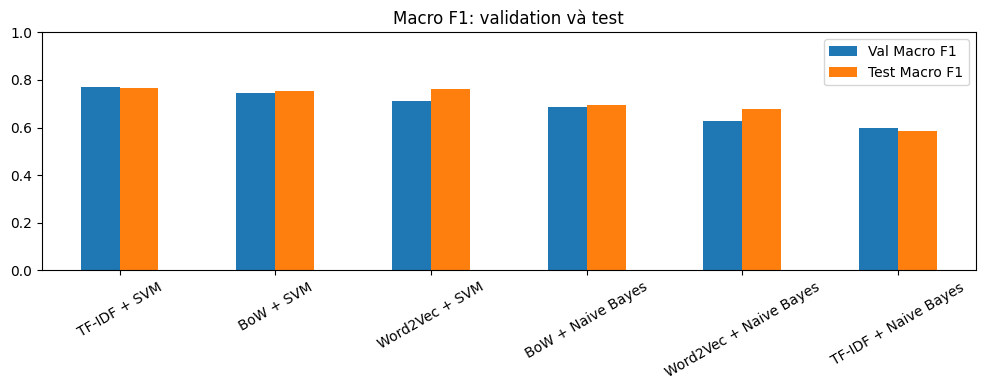

In [29]:
ve = scores[scores['Feature'] != '(baseline)']
ve = ve.set_index(ve['Feature'] + ' + ' + ve['Model'])
ve[['Val Macro F1', 'Macro F1']].rename(columns={'Macro F1': 'Test Macro F1'}).plot(kind='bar', figsize=(10, 4), rot=30)
plt.ylim(0, 1); plt.title('Macro F1: validation và test'); plt.tight_layout(); plt.show()

### Mô hình tốt nhất (chọn theo validation): ma trận nhầm lẫn và báo cáo trên test

Mô hình chọn: TF-IDF + SVM


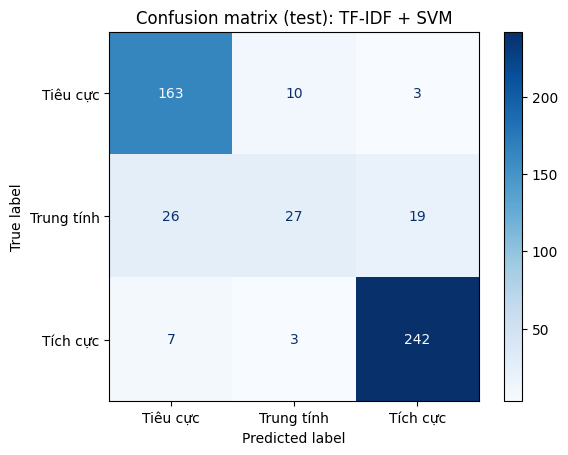

              precision    recall  f1-score   support

    Tiêu cực     0.8316    0.9261    0.8763       176
  Trung tính     0.6750    0.3750    0.4821        72
    Tích cực     0.9167    0.9603    0.9380       252

    accuracy                         0.8640       500
   macro avg     0.8078    0.7538    0.7655       500
weighted avg     0.8519    0.8640    0.8506       500



In [30]:
best = tuple(scores.loc[scores['Feature'] != '(baseline)'].iloc[0][['Feature', 'Model']])
print('Mô hình chọn:', ' + '.join(best))
ConfusionMatrixDisplay(confusion_matrix(y['test'], predictions[best], labels=LABELS), display_labels=NAMES).plot(cmap='Blues')
plt.title('Confusion matrix (test): ' + ' + '.join(best)); plt.show()
print(classification_report(y['test'], predictions[best], labels=LABELS, target_names=NAMES, digits=4, zero_division=0))

### Phân tích lỗi

In [31]:
sai = test[['noi_dung', 'so_sao', 'label']].assign(du_doan=predictions[best]).query('label != du_doan')
print(f'{len(sai)}/{len(test)} câu đoán sai')
sai.head(12)

68/500 câu đoán sai


,noi_dung,so_sao,label,du_doan
43,sp mới mà mới vừa đổ nước vào là bị rỉ chỗ nút xả cặn,1,-1,0
189,Ủa sao để giá 3990k. Mjh mua hôm qua tại điện máy xanh phường hóa an TP Biên Hòa giá 4290k,3,0,1
215,Máy vận hành hơi tiếng ồn,3,-1,1
232,"Quạt hơi ồn,nhưng sài tốt",3,0,1
244,"Mới mua lúc 7h tối. đổ nước vào thì có hiện tượng rò ra từ nút xả cặn,",3,-1,0
312,Tôi cần hỗ trợ,4,0,-1
330,Hệ thống cánh tản gió hơi chậm độ mở rộng hướng gió hơi hẹp. Cần mở rộng phạm vi gió tốc độ quay của đảo gió giảm ồn,4,0,-1
595,Em nói thật chứ mấy bác nên đọc kĩ hướng dẫn rồi hẵng sử dung Máy ngon trong tầm giá mát nói chung chỉ thế thôi.kaka,5,0,1
600,Máy làm mát tốt. Nhưng có cái hơi ồn. Và sáng dậy nước lênh láng nhà. Noia chung là cảm thấy tốt,5,0,1
669,"Mới mua chưa được nổi 2 tháng đã hỏng, không biết có được bảo hành không, quá chán",1,-1,0


In [32]:
scores.to_csv(OUT / 'model_scores.csv', index=False, encoding='utf-8-sig')
print('Đã lưu out/model_scores.csv')

Đã lưu out/model_scores.csv
